# Customer Product Recommendation Model
## Armstrong Hirwa: data preparation, feature engineering, modelling and evaluation

**Prepared by:** Armstrong Hirwa
**Project objective:** Combine customer social-profile information with transaction history and train a classification model to predict the product category associated with a customer.

### What this notebook does
1. Loads and inspects both source datasets.
2. Cleans customer identifiers, duplicates, missing values and data types.
3. Aggregates multiple social profiles to one row per customer.
4. Creates historical purchasing features using only earlier transactions.
5. Merges social and transaction data and validates the result.
6. Explores the merged data and defines model predictors and target.
7. Trains and evaluates Random Forest and Logistic Regression classifiers.
8. Saves the merged dataset, trained pipeline and evaluation results, and shows the `predict()` function used by the command-line app.

All logic lives in `product_model.py`. This notebook imports it and shows the result of every stage, so the notebook and the command-line app use exactly the same code.

## 1. Environment and imports

In [1]:
import sys
import json
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

HERE = Path.cwd() if (Path.cwd() / "product_model.py").exists() else Path.cwd() / "armstrong_product_model"
sys.path.insert(0, str(HERE))
import product_model as pm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

## 2. Load the two datasets

The transaction file contains the purchase outcome we want to predict. The social-profile file contains customer signals that may help explain purchasing behaviour.

In [2]:
transactions_raw = pd.read_csv(pm.TRANSACTIONS_FILE)
social_raw = pd.read_csv(pm.SOCIAL_FILE)

print("Transactions shape:", transactions_raw.shape)
print("Social profiles shape:", social_raw.shape)
display(transactions_raw.head())
display(social_raw.head())

Transactions shape: (150, 6)
Social profiles shape: (155, 5)


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


## 3. Understand the raw data

Before changing anything, inspect column names, data types, missing values and duplicate rows. This helps us catch unexpected source-data issues early.

In [3]:
print("TRANSACTIONS INFO")
transactions_raw.info()
print("\nSOCIAL PROFILES INFO")
social_raw.info()

TRANSACTIONS INFO
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    str    
 4   product_category    150 non-null    str    
 5   customer_rating     140 non-null    float64
dtypes: float64(1), int64(3), str(2)
memory usage: 7.2 KB

SOCIAL PROFILES INFO
<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id_new          155 non-null    str    
 1   social_media_platform    155 non-null    str    
 2   engagement_score         155 non-null    int64  
 3   purchase_interest_score  155 non-null    float64


In [4]:
inspection = pd.DataFrame({
    "transactions_missing": transactions_raw.isna().sum(),
    "social_missing": social_raw.isna().sum(),
})
display(inspection)
print("Exact duplicate transaction rows:", transactions_raw.duplicated().sum())
print("Exact duplicate social rows:", social_raw.duplicated().sum())
print("Social profile rows per customer:", social_raw.groupby("customer_id_new").size().value_counts().sort_index().to_dict())

,transactions_missing,social_missing
customer_id_legacy,0.0,NaN
customer_id_new,NaN,0.0
customer_rating,10.0,NaN
engagement_score,NaN,0.0
product_category,0.0,NaN
purchase_amount,0.0,NaN
purchase_date,0.0,NaN
purchase_interest_score,NaN,0.0
review_sentiment,NaN,0.0
social_media_platform,NaN,0.0


Exact duplicate transaction rows: 0
Exact duplicate social rows: 5
Social profile rows per customer: {1: 43, 2: 22, 3: 14, 4: 1, 5: 3, 7: 1}


## 4. Clean the datasets

### Cleaning decisions
- Remove exact duplicate rows (5 duplicated social-profile rows).
- Convert `purchase_date` to a date and the amount, rating and score columns to numbers; invalid entries become missing values.
- Fill the 10 missing `customer_rating` values with the median rating, which is robust to extreme values.
- Standardise both customer ID formats into a common numeric `customer_id` (`151` and `A151` → `151`).
- Keep missing social scores for now; they are imputed inside the model pipeline.

In [5]:
transactions, social_profiles = pm.load_clean()

print("Transactions after cleaning:", transactions.shape)
print("Social profiles after cleaning:", social_profiles.shape)
print("Missing customer_rating after cleaning:", transactions["customer_rating"].isna().sum())
display(transactions.dtypes.to_frame("dtype").T)

Transactions after cleaning: (150, 7)
Social profiles after cleaning: (150, 6)
Missing customer_rating after cleaning: 0


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id
dtype,int64,int64,int64,datetime64[us],str,float64,int64


## 5. Validate customer identifiers

A merge only works when the same customer is represented consistently in both datasets. We compare unique customer IDs before merging.

In [6]:
transaction_ids = set(transactions["customer_id"].dropna())
social_ids = set(social_profiles["customer_id"].dropna())

print("Unique transaction customers:", len(transaction_ids))
print("Unique social customers:", len(social_ids))
print("Customers present in both:", len(transaction_ids & social_ids))
print("Transaction customers without a social profile:", len(transaction_ids - social_ids))

Unique transaction customers: 75
Unique social customers: 84
Customers present in both: 61
Transaction customers without a social profile: 14


## 6. Aggregate social profiles to one row per customer

A customer may have multiple social-platform records. Joining those raw rows directly to transactions could duplicate each transaction. We aggregate social profiles so there is exactly one row per customer:

- number of distinct platforms and the most frequent platform;
- mean engagement and purchase-interest scores;
- most frequent review sentiment;
- an engagement level (High ≥ 70, Medium ≥ 40, otherwise Low).

In [7]:
social_aggregated = pm.aggregate_social(social_profiles)

print("Aggregated social rows:", len(social_aggregated))
print("Unique customer IDs:", social_aggregated["customer_id"].nunique())
display(social_aggregated.head())

Aggregated social rows: 84
Unique customer IDs: 84


,customer_id,social_media_platform_nunique,social_media_platform_most_common_value,engagement_score_mean,purchase_interest_score_mean,review_sentiment_most_common_value,social_platform_count,engagement_level
0,100,2,Instagram,77.000000,4.400000,Negative,2,High
1,101,1,Twitter,68.000000,1.000000,Neutral,1,Medium
2,102,1,LinkedIn,51.000000,4.800000,Neutral,1,Medium
3,103,2,Instagram,64.333333,2.866667,Positive,2,Medium
4,104,2,Twitter,83.000000,2.933333,Negative,2,High


## 7. Feature engineering: historical purchase behaviour

For each transaction, create:
- `prior_purchase_count`: number of earlier transactions for that customer.
- `prior_avg_purchase_amount`: average amount from earlier transactions.
- `prior_avg_customer_rating`: average rating from earlier transactions.

We sort by customer and purchase date. `shift(1)` excludes the current transaction from its own history, so no information from the future leaks into a prediction. A customer's first transaction has no history and therefore receives missing historical averages; the model imputes those values.

In [8]:
history = pm.add_history_features(transactions)
display(history[["customer_id", "purchase_date", "product_category", "purchase_amount",
                 "prior_purchase_count", "prior_avg_purchase_amount", "prior_avg_customer_rating"]].head(8))

,customer_id,purchase_date,product_category,purchase_amount,prior_purchase_count,prior_avg_purchase_amount,prior_avg_customer_rating
112,100,2024-04-22,Clothing,172,0,NaN,NaN
146,100,2024-05-26,Books,387,1,172.000000,4.000000
16,101,2024-01-17,Books,271,0,NaN,NaN
20,101,2024-01-21,Groceries,192,1,271.000000,2.100000
58,101,2024-02-28,Books,408,2,231.500000,2.750000
72,101,2024-03-13,Books,145,3,290.333333,2.666667
13,102,2024-01-14,Electronics,101,0,NaN,NaN
44,102,2024-02-14,Electronics,380,1,101.000000,3.200000


## 8. Merge transaction and social data

We use a **left join** with transactions on the left and aggregated social profiles on the right.

**Why a left join?** The target is the product category recorded in transactions. A left join keeps every transaction even when a customer has no matching social profile. An inner join would drop those transactions, and with only 150 rows that loss matters. Missing social features are handled later by the model's imputation steps.

In [9]:
merged_dataset = pm.build_dataset()  # also asserts row count and transaction uniqueness

has_profile = merged_dataset["engagement_score_mean"].notna()
print("Transactions before merge:", len(transactions))
print("Rows after merge:", len(merged_dataset))
print("Duplicate transaction IDs:", merged_dataset["transaction_id"].duplicated().sum())
print("Transactions matched to a social profile:", has_profile.sum())
print("Transactions without a social profile:", (~has_profile).sum(),
      f"({merged_dataset.loc[~has_profile, 'customer_id'].nunique()} customers)")
print("Saved:", pm.MERGED_FILE.name, merged_dataset.shape)

Transactions before merge: 150
Rows after merge: 150
Duplicate transaction IDs: 0
Transactions matched to a social profile: 117
Transactions without a social profile: 33 (14 customers)
Saved: merged_dataset.csv (150, 17)


**Post-merge checks.** The row count is unchanged (150 → 150) and there are no duplicate transaction IDs, so aggregating the profiles before the join worked. The 33 transactions without a social profile come from 14 customers who appear only in the transaction file; the left join keeps them as intended.

## 9. Inspect the merged dataset

In [10]:
display(merged_dataset.isna().sum().to_frame("missing_count").query("missing_count > 0"))
display(merged_dataset["product_category"].value_counts().to_frame("transaction_count"))

,missing_count
prior_avg_purchase_amount,75
prior_avg_customer_rating,75
social_media_platform_nunique,33
social_media_platform_most_common_value,33
engagement_score_mean,33
purchase_interest_score_mean,33
review_sentiment_most_common_value,33
social_platform_count,33
engagement_level,33


,transaction_count
product_category,
Sports,35
Electronics,34
Clothing,28
Groceries,28
Books,25


## 10. Exploratory data analysis

A few plots to understand the target and the social features before modelling. The full EDA (variable types, distributions, outliers, correlations and statistical tests) is in `notebooks/eda_merged_dataset.ipynb`.

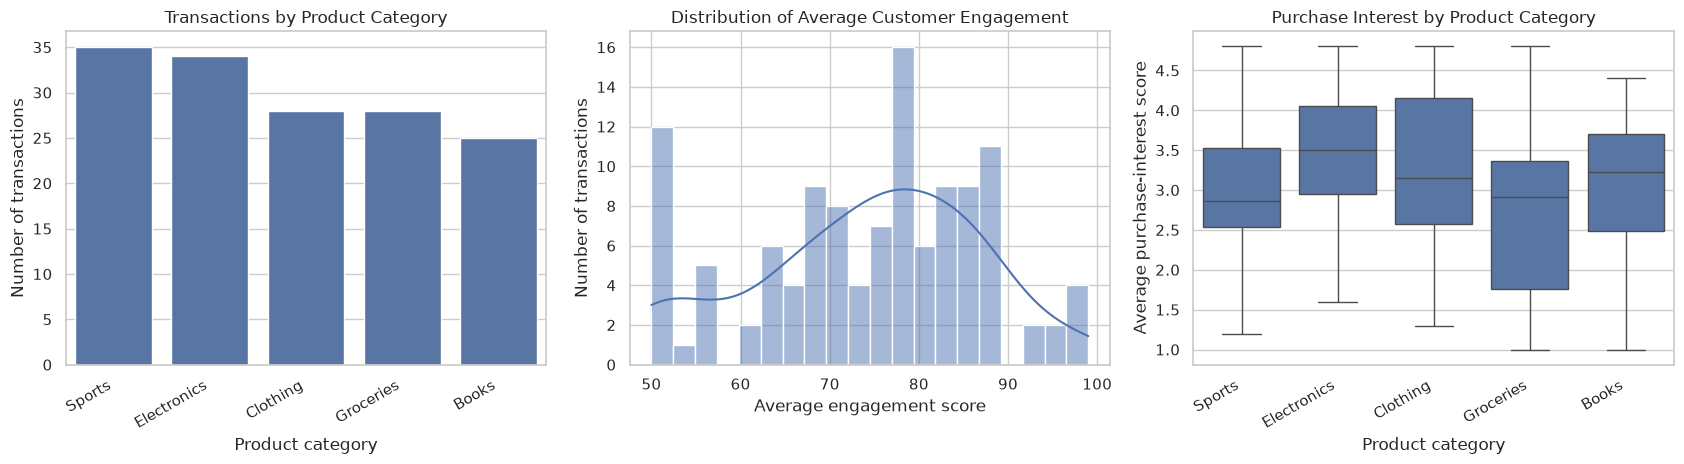

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = merged_dataset["product_category"].value_counts().index

sns.countplot(data=merged_dataset, x="product_category", order=order, ax=axes[0])
axes[0].set_title("Transactions by Product Category")
axes[0].set_xlabel("Product category"); axes[0].set_ylabel("Number of transactions")

sns.histplot(data=merged_dataset, x="engagement_score_mean", bins=20, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Average Customer Engagement")
axes[1].set_xlabel("Average engagement score"); axes[1].set_ylabel("Number of transactions")

sns.boxplot(data=merged_dataset, x="product_category", y="purchase_interest_score_mean", order=order, ax=axes[2])
axes[2].set_title("Purchase Interest by Product Category")
axes[2].set_xlabel("Product category"); axes[2].set_ylabel("Average purchase-interest score")

for ax in (axes[0], axes[2]):
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.show()

The five categories are close to balanced (25–35 transactions each), so random guessing would score about 20% accuracy. Engagement is concentrated between 65 and 90, and purchase interest looks very similar across categories, which is an early sign that these features carry little information about the product chosen.

## 11. Define features (`X`) and target (`y`)

The model predicts `product_category`.

Predictors include social engagement, purchase interest, platform usage and historical purchasing behaviour. We deliberately exclude:
- `product_category` from `X`, because it is the target;
- `purchase_amount` and `customer_rating` of the current transaction, because they are only known after the purchase;
- customer and transaction IDs, because they identify records rather than describe behaviour;
- `social_media_platform_nunique`, because it is identical to `social_platform_count`.

In [12]:
X = merged_dataset[pm.FEATURES]
y = merged_dataset[pm.TARGET].astype(str)
print("Numeric features:", pm.NUMERIC_FEATURES)
print("Categorical features:", pm.CATEGORICAL_FEATURES)
print("Rows:", len(X), "| Classes:", sorted(y.unique()))

Numeric features: ['engagement_score_mean', 'purchase_interest_score_mean', 'social_platform_count', 'prior_purchase_count', 'prior_avg_purchase_amount', 'prior_avg_customer_rating']
Categorical features: ['social_media_platform_most_common_value', 'review_sentiment_most_common_value']
Rows: 150 | Classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']


## 12. Evaluation design: cross-validation grouped by customer

A random row split could place transactions from the same customer in both training and test sets, which makes evaluation too optimistic. We use **5-fold `GroupKFold` by customer**: each customer's transactions stay together, and every transaction is predicted exactly once by a model that never saw that customer.

With only 150 rows, a single 75/25 split gives very noisy scores (40 test rows), so cross-validation is more reliable.

Metrics:
- **Accuracy:** fraction of predictions that are correct.
- **Macro F1:** harmonic mean of precision and recall, averaged so each category counts equally.
- **Log loss:** quality of the predicted probabilities (lower is better). Random guessing over 5 classes scores ln 5 ≈ 1.609.

Both models are strongly regularised (Random Forest: at least 10 samples per leaf; Logistic Regression: C = 0.05). With so little signal, more flexible settings become overconfident and their log loss gets worse than random guessing.

In [13]:
results = {}
for name, make in pm.CANDIDATES.items():
    scores, y_true, y_pred, classes = pm.cross_validate(merged_dataset, make)
    results[name] = (scores, y_true, y_pred, classes)

comparison = pd.DataFrame({name: r[0] for name, r in results.items()}).T
comparison.loc["Random guessing"] = [1 / y.nunique(), np.nan, np.nan, np.log(y.nunique())]
display(comparison.round(3))

,accuracy,f1_macro,f1_weighted,log_loss
LogisticRegression,0.187,0.170,0.173,1.653
RandomForest,0.200,0.191,0.190,1.655
Random guessing,0.200,NaN,NaN,1.609


## 13. Confusion matrix of the selected model

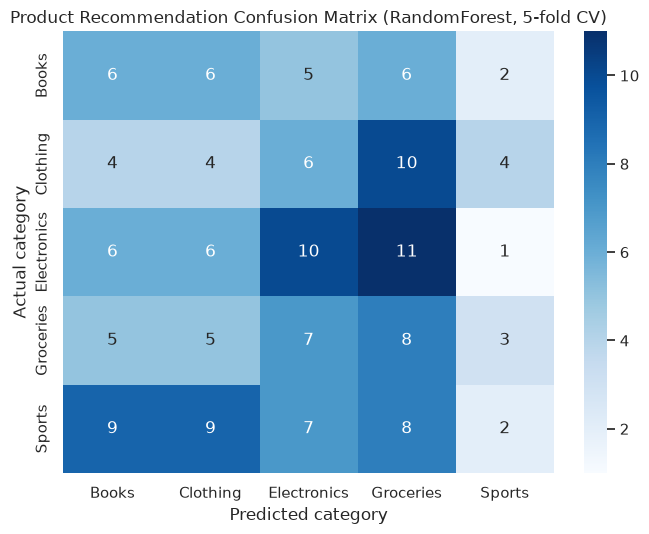

              precision    recall  f1-score   support

       Books       0.20      0.24      0.22        25
    Clothing       0.13      0.14      0.14        28
 Electronics       0.29      0.29      0.29        34
   Groceries       0.19      0.29      0.23        28
      Sports       0.17      0.06      0.09        35

    accuracy                           0.20       150
   macro avg       0.19      0.20      0.19       150
weighted avg       0.20      0.20      0.19       150



In [14]:
best = min(results, key=lambda n: (-results[n][0]["f1_macro"], results[n][0]["log_loss"]))
_, y_true, y_pred, classes = results[best]

from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_true, y_pred, labels=classes)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title(f"Product Recommendation Confusion Matrix ({best}, 5-fold CV)")
plt.xlabel("Predicted category"); plt.ylabel("Actual category")
plt.tight_layout(); plt.show()

print(classification_report(y_true, y_pred, zero_division=0))

**Interpretation.** Both models score at the level of random guessing: about 0.20 accuracy and a log loss close to 1.609. The confusion matrix has no strong diagonal; predictions are spread across all categories. This matches the EDA, which found no feature significantly associated with `product_category` (every p-value above 0.05). The limit comes from the data (150 transactions with very little signal), not from the choice of algorithm. Random Forest is selected because it has the higher macro F1, with practically the same log loss.

## 14. Train the final model and save the deliverables

`pm.train()` repeats the evaluation, fits the selected model on all 150 transactions, and saves:
- `merged_dataset.csv`: the cleaned, merged, feature-engineered dataset;
- `product_recommendation_model.joblib`: the fitted preprocessing + classifier pipeline;
- `product_metrics.json`: all evaluation scores;
- `product_confusion_matrix.png`: the confusion matrix above.

In [15]:
metrics = pm.train()
print("Selected model:", metrics["selected_model"])
print(json.dumps(metrics["models"], indent=2))
for f in [pm.MERGED_FILE, pm.MODEL_FILE, pm.METRICS_FILE, pm.CONFUSION_FILE]:
    print(f"{f.name:<40} exists: {f.exists()}  ({f.stat().st_size:,} bytes)")

Selected model: RandomForest
{
  "LogisticRegression": {
    "accuracy": 0.187,
    "f1_macro": 0.17,
    "f1_weighted": 0.173,
    "log_loss": 1.653
  },
  "RandomForest": {
    "accuracy": 0.2,
    "f1_macro": 0.191,
    "f1_weighted": 0.19,
    "log_loss": 1.655
  }
}
merged_dataset.csv                       exists: True  (13,386 bytes)
product_recommendation_model.joblib      exists: True  (521,293 bytes)
product_metrics.json                     exists: True  (1,606 bytes)
product_confusion_matrix.png             exists: True  (53,293 bytes)


## 15. Feature importance

Feature importance shows which transformed predictors the fitted forest relied on most. It is not a causal explanation, and with this little signal the differences between features are small.

In [16]:
import joblib
final = joblib.load(pm.MODEL_FILE)["model"]
forest = final.named_steps["classifier"]
if hasattr(forest, "feature_importances_"):
    importance = (pd.DataFrame({"feature": final.named_steps["preprocess"].get_feature_names_out(),
                                "importance": forest.feature_importances_})
                  .sort_values("importance", ascending=False).head(12))
    plt.figure(figsize=(9, 5))
    sns.barplot(data=importance, x="importance", y="feature")
    plt.title("Top Random Forest Feature Importances")
    plt.xlabel("Importance"); plt.ylabel("Transformed feature")
    plt.tight_layout(); plt.show()

## 16. The `predict()` function used by the command-line app

After a user passes face recognition, `main.py` calls `product_model.predict(customer_id)`. The function builds the customer's **next-purchase** profile from their full purchase history and social profile, then returns the most likely category. With `top_k` it returns a ranked list with probabilities, which is a more honest way to present a recommendation from a weak model.

Each team member is linked to one real customer who appears in both source datasets:

In [17]:
member_customers = {"armstrong": 187, "ayomide": 114, "fadhili": 101, "diane": 188}
rows = []
for member, customer_id in member_customers.items():
    ranked = pm.predict(customer_id, top_k=3)
    rows.append({"member": member, "customer_id": customer_id,
                 "recommended": pm.predict(customer_id),
                 "top_3": ", ".join(f"{c} ({p:.0%})" for c, p in ranked)})
display(pd.DataFrame(rows))

,member,customer_id,recommended,top_3
0,armstrong,187,Sports,"Sports (33%), Books (24%), Clothing (21%)"
1,ayomide,114,Clothing,"Clothing (30%), Books (22%), Sports (21%)"
2,fadhili,101,Books,"Books (24%), Sports (23%), Groceries (21%)"
3,diane,188,Electronics,"Electronics (26%), Sports (25%), Books (20%)"


## 17. Conclusions and limitations

- **Data preparation works as intended.** The two datasets were cleaned, their IDs aligned, the social profiles aggregated to one row per customer, and the left join kept all 150 transactions with no duplicates.
- **Leak-free features.** History features use only earlier purchases, and evaluation keeps each customer's transactions together.
- **Predictive power is at chance level.** No model beats random guessing on this data. The features do not carry information about which category a customer buys, and the regular one-transaction-per-day pattern suggests the dataset is synthetic.
- **What would help:** more transactions per customer, and features closer to the purchase decision (browsing history, basket contents, time of year).
- **In the system,** the model is wired into the authentication flow and returns a recommendation with probabilities; its accuracy should be read as a property of this dataset rather than of the pipeline.